# Downloading the data



In [ ]:
!pip install roboflow ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 20.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.3 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key="cBdWFTrDUSgyPgbEuz8m")
project = rf.workspace("bahraini-traditional-food").project("bahraini-traditional-food-2iu6f")
version = project.version(1)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bahraini-Traditional-Food-1 in yolo26:: 100%|██████████| 1253/1253 [00:00<00:00, 4073.15it/s]


# Pretrained Model

In [ ]:
from ultralytics import YOLO
model = YOLO("yolo26s.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


# Quality Check

In [ ]:
import os

dataset_path = "dataset"

for split in ["train", "valid", "test"]:
  image_path = os.path.join("/content/Bahraini-Traditional-Food-1", split, "images")
  images = os.listdir(image_path)

  print(f"{split}: {len(images)} images")

train: 546 images
valid: 52 images
test: 26 images


In [ ]:
import yaml

with open(f'{dataset.location}/data.yaml', 'r') as file:
  data = yaml.safe_load(file)

print(data['names'])

['Arabic coffee', 'Balaleet', 'Chicken Majboos', 'Halwa', 'Harees', 'Khanfaroosh', 'Meat Majboos', 'Tikka', 'Zalabiya', 'karak']


# Finetuning

In [ ]:
model.train(data='/content/Bahraini-Traditional-Food-1/data.yaml', epochs=5)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bahraini-Traditional-Food-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7903428d9b50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [ ]:
finetuned_model = YOLO('/content/runs/detect/train/weights/best.pt')

In [ ]:
results = finetuned_model("/content/Bahraini-Traditional-Food-1/valid/images/OIP-57-_webp.rf.2a8c325626387d02699a8079fa1ce8e8.jpg")


image 1/1 /content/Bahraini-Traditional-Food-1/valid/images/OIP-57-_webp.rf.2a8c325626387d02699a8079fa1ce8e8.jpg: 640x640 1 Arabic coffee, 37.5ms
Speed: 3.6ms preprocess, 37.5ms inference, 6.5ms postprocess per image at shape (1, 3, 640, 640)


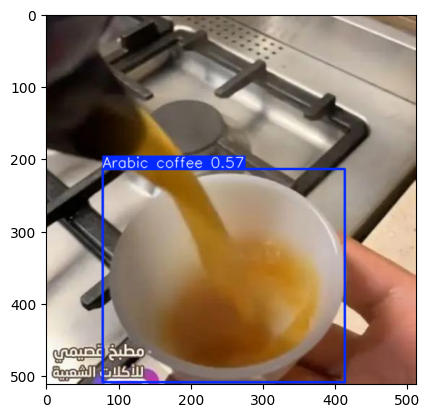

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1])

# More epochs

In [ ]:
finetuned_model = YOLO('/content/runs/detect/train/weights/last.pt')

finetuned_model.train(data='/content/Bahraini-Traditional-Food-1/data.yaml', epochs=10)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bahraini-Traditional-Food-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/train/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nb

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79034286d610>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [ ]:
finetuned_model = YOLO('/content/runs/detect/train-2/weights/best.pt')

In [ ]:
results = finetuned_model("/content/Bahraini-Traditional-Food-1/valid/images/OIP-57-_webp.rf.2a8c325626387d02699a8079fa1ce8e8.jpg")


image 1/1 /content/Bahraini-Traditional-Food-1/valid/images/OIP-57-_webp.rf.2a8c325626387d02699a8079fa1ce8e8.jpg: 640x640 1 Arabic coffee, 52.7ms
Speed: 11.8ms preprocess, 52.7ms inference, 6.3ms postprocess per image at shape (1, 3, 640, 640)


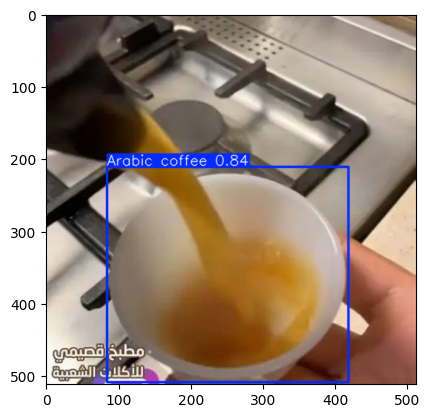

In [ ]:
plt.imshow(results[0].plot()[..., ::-1])


image 1/1 /content/Bahraini-Traditional-Food-1/valid/images/images-14-_jpg.rf.58ff3acaab3a8ed443a645cab5e9adde.jpg: 640x640 1 Tikka, 23.1ms
Speed: 2.5ms preprocess, 23.1ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


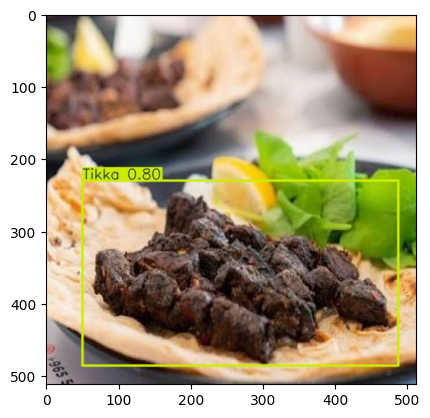

In [ ]:
results = finetuned_model("/content/Bahraini-Traditional-Food-1/valid/images/images-14-_jpg.rf.58ff3acaab3a8ed443a645cab5e9adde.jpg")
plt.imshow(results[0].plot()[..., ::-1])

# Evaluation

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 982.3±283.4 MB/s, size: 34.7 KB)
val: Scanning /content/Bahraini-Traditional-Food-1/valid/labels.cache... 52 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 52/52 13.6Mit/s 0.0s
val: /content/Bahraini-Traditional-Food-1/valid/images/istockphoto-1308304495-612x612-Copy_jpg.rf.625fff857d8acbf801b122411fdbe2bd.jpg: ignoring corrupt image/label: labels mix segment and detection rows
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 2.9s
                   all         51         83      0.805      0.809      0.849      0.661
         Arabic coffee          6          6      0.675      0.833      0.826      0.589
              Balaleet          2          2      0.847          1      0.995      0.795
    

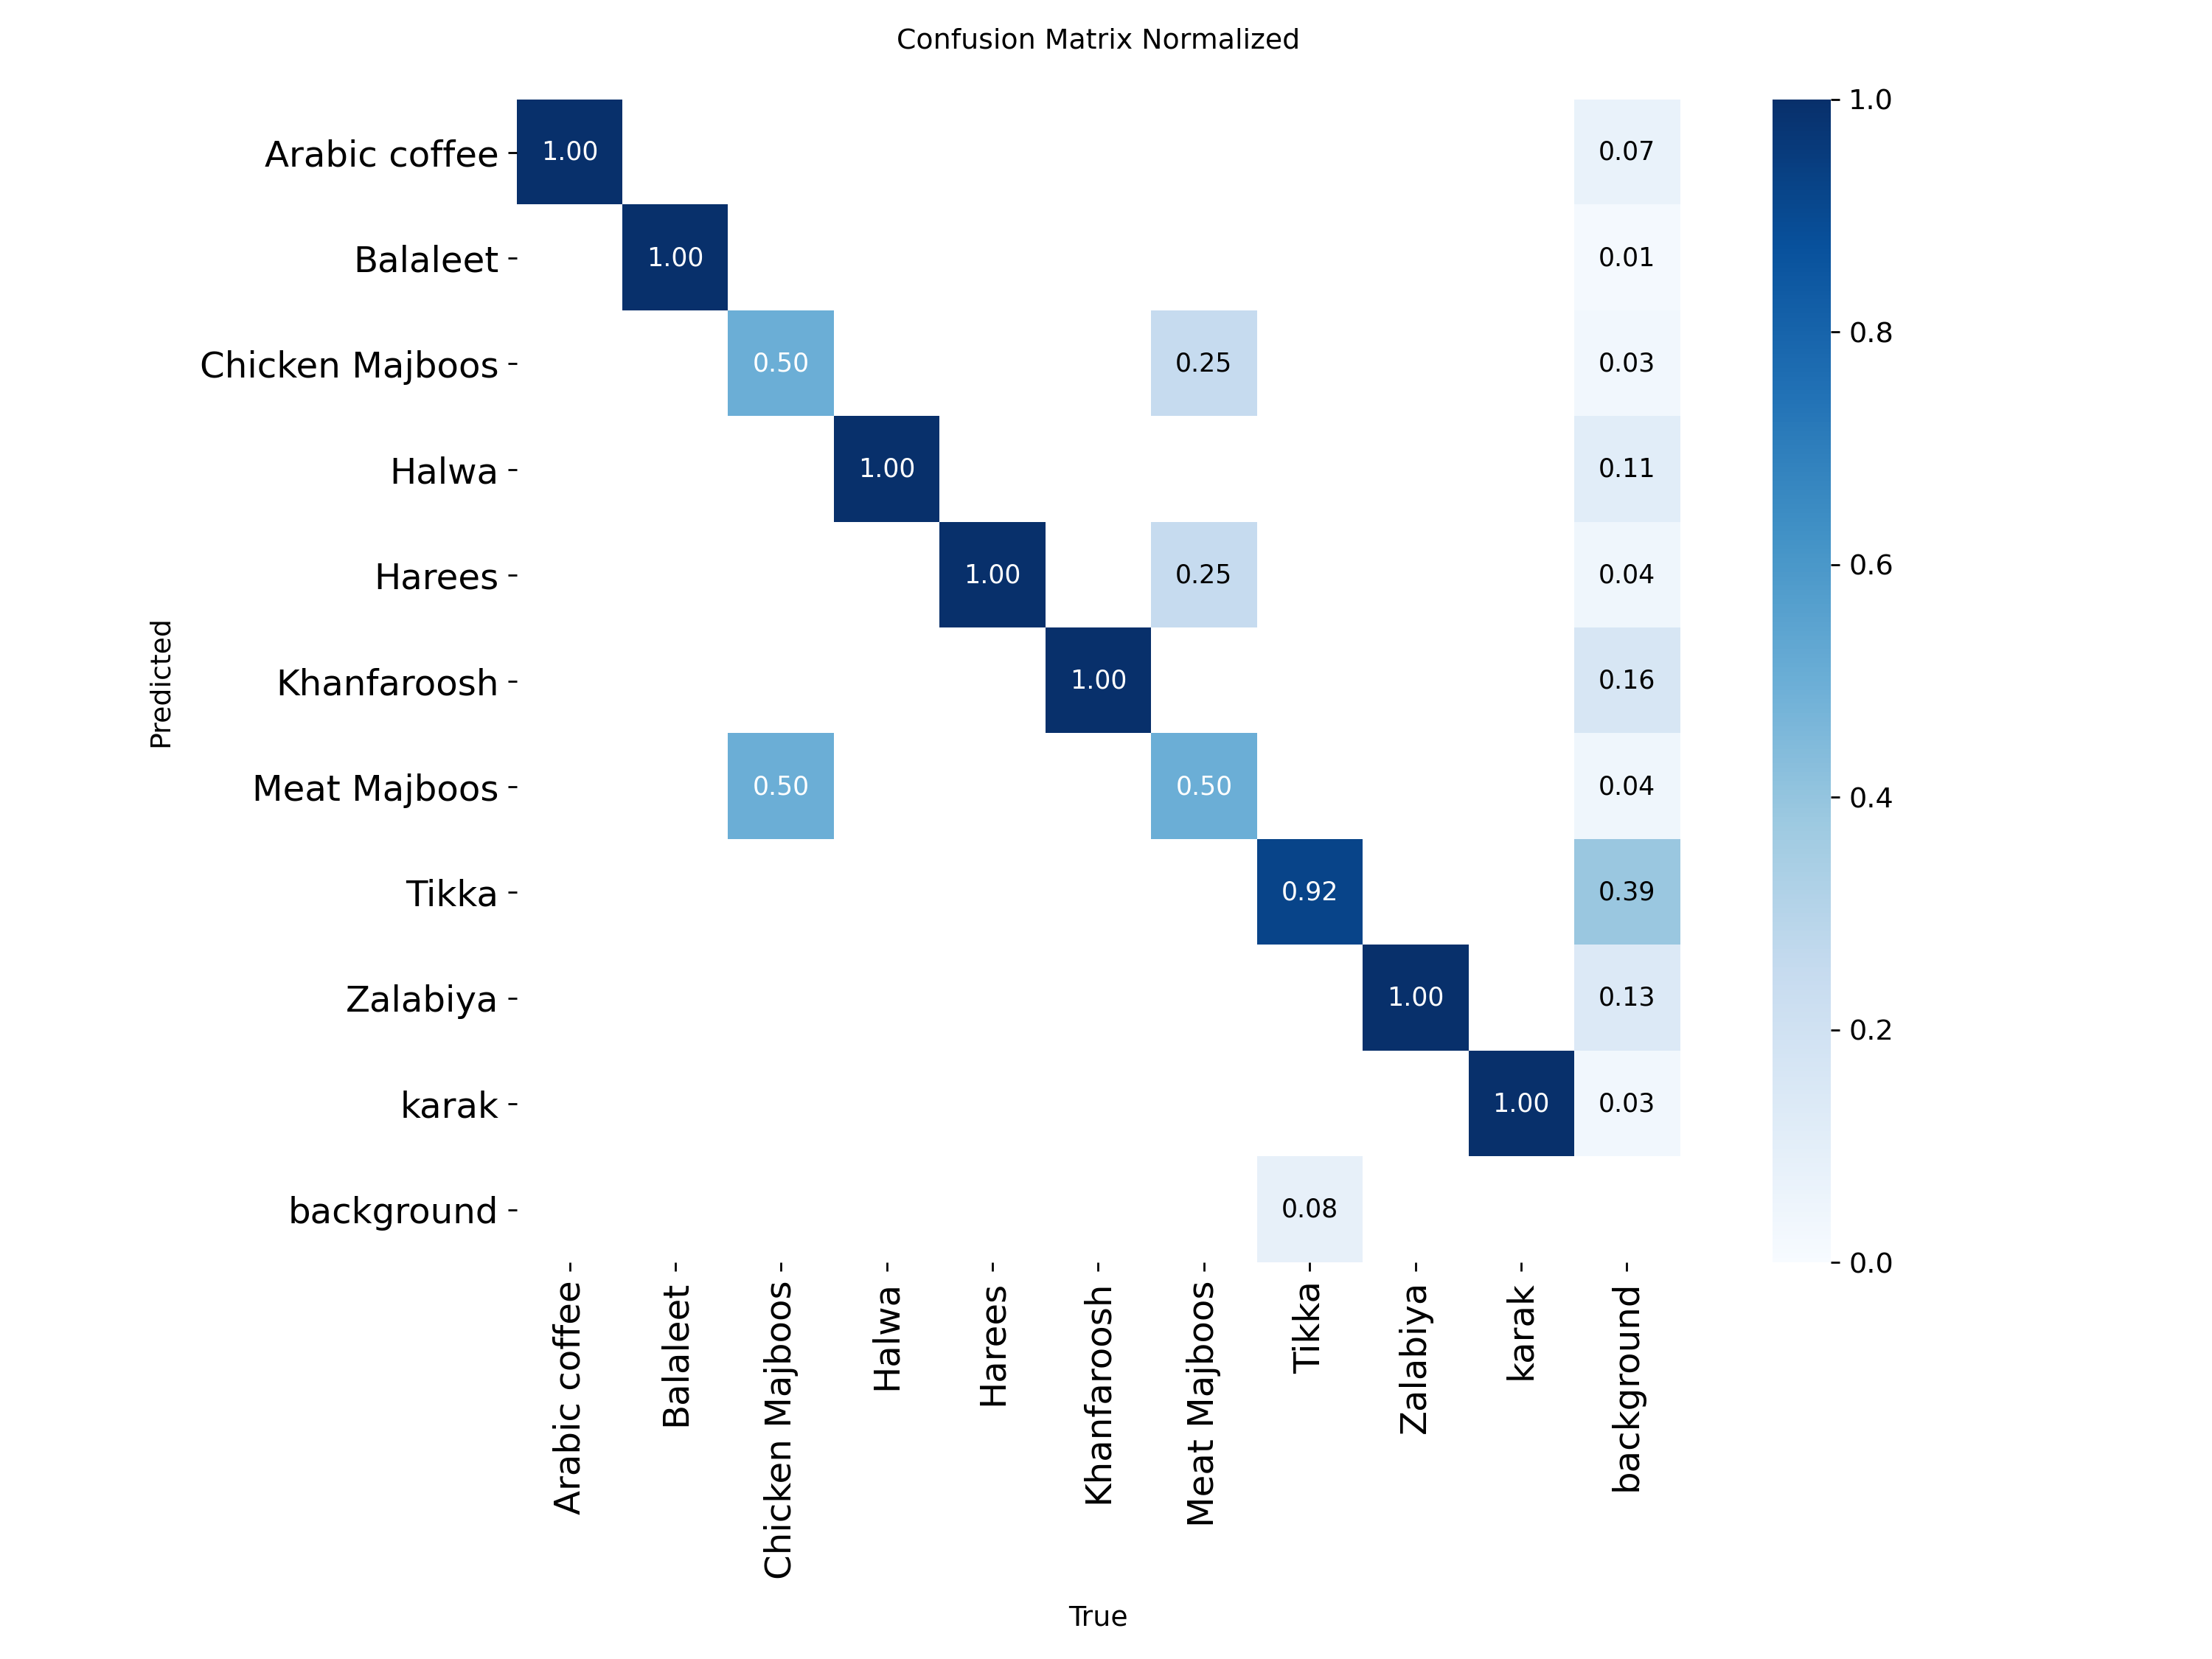

In [ ]:
from IPython.display import Image, display
metrics = finetuned_model.val(data="/content/Bahraini-Traditional-Food-1/data.yaml", split="val")
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
display(Image(f"{metrics.save_dir}/confusion_matrix_normalized.png"))

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 906.3±370.7 MB/s, size: 31.7 KB)
val: Scanning /content/Bahraini-Traditional-Food-1/test/labels.cache... 26 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 6.8Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 4, len(boxes) = 44. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.7it/s 1.2s
                   all         26         44      0.726      0.881      0.791      0.591
         Arabic coffee          1          1      0.125          1      0.199      0.119
              Balaleet        

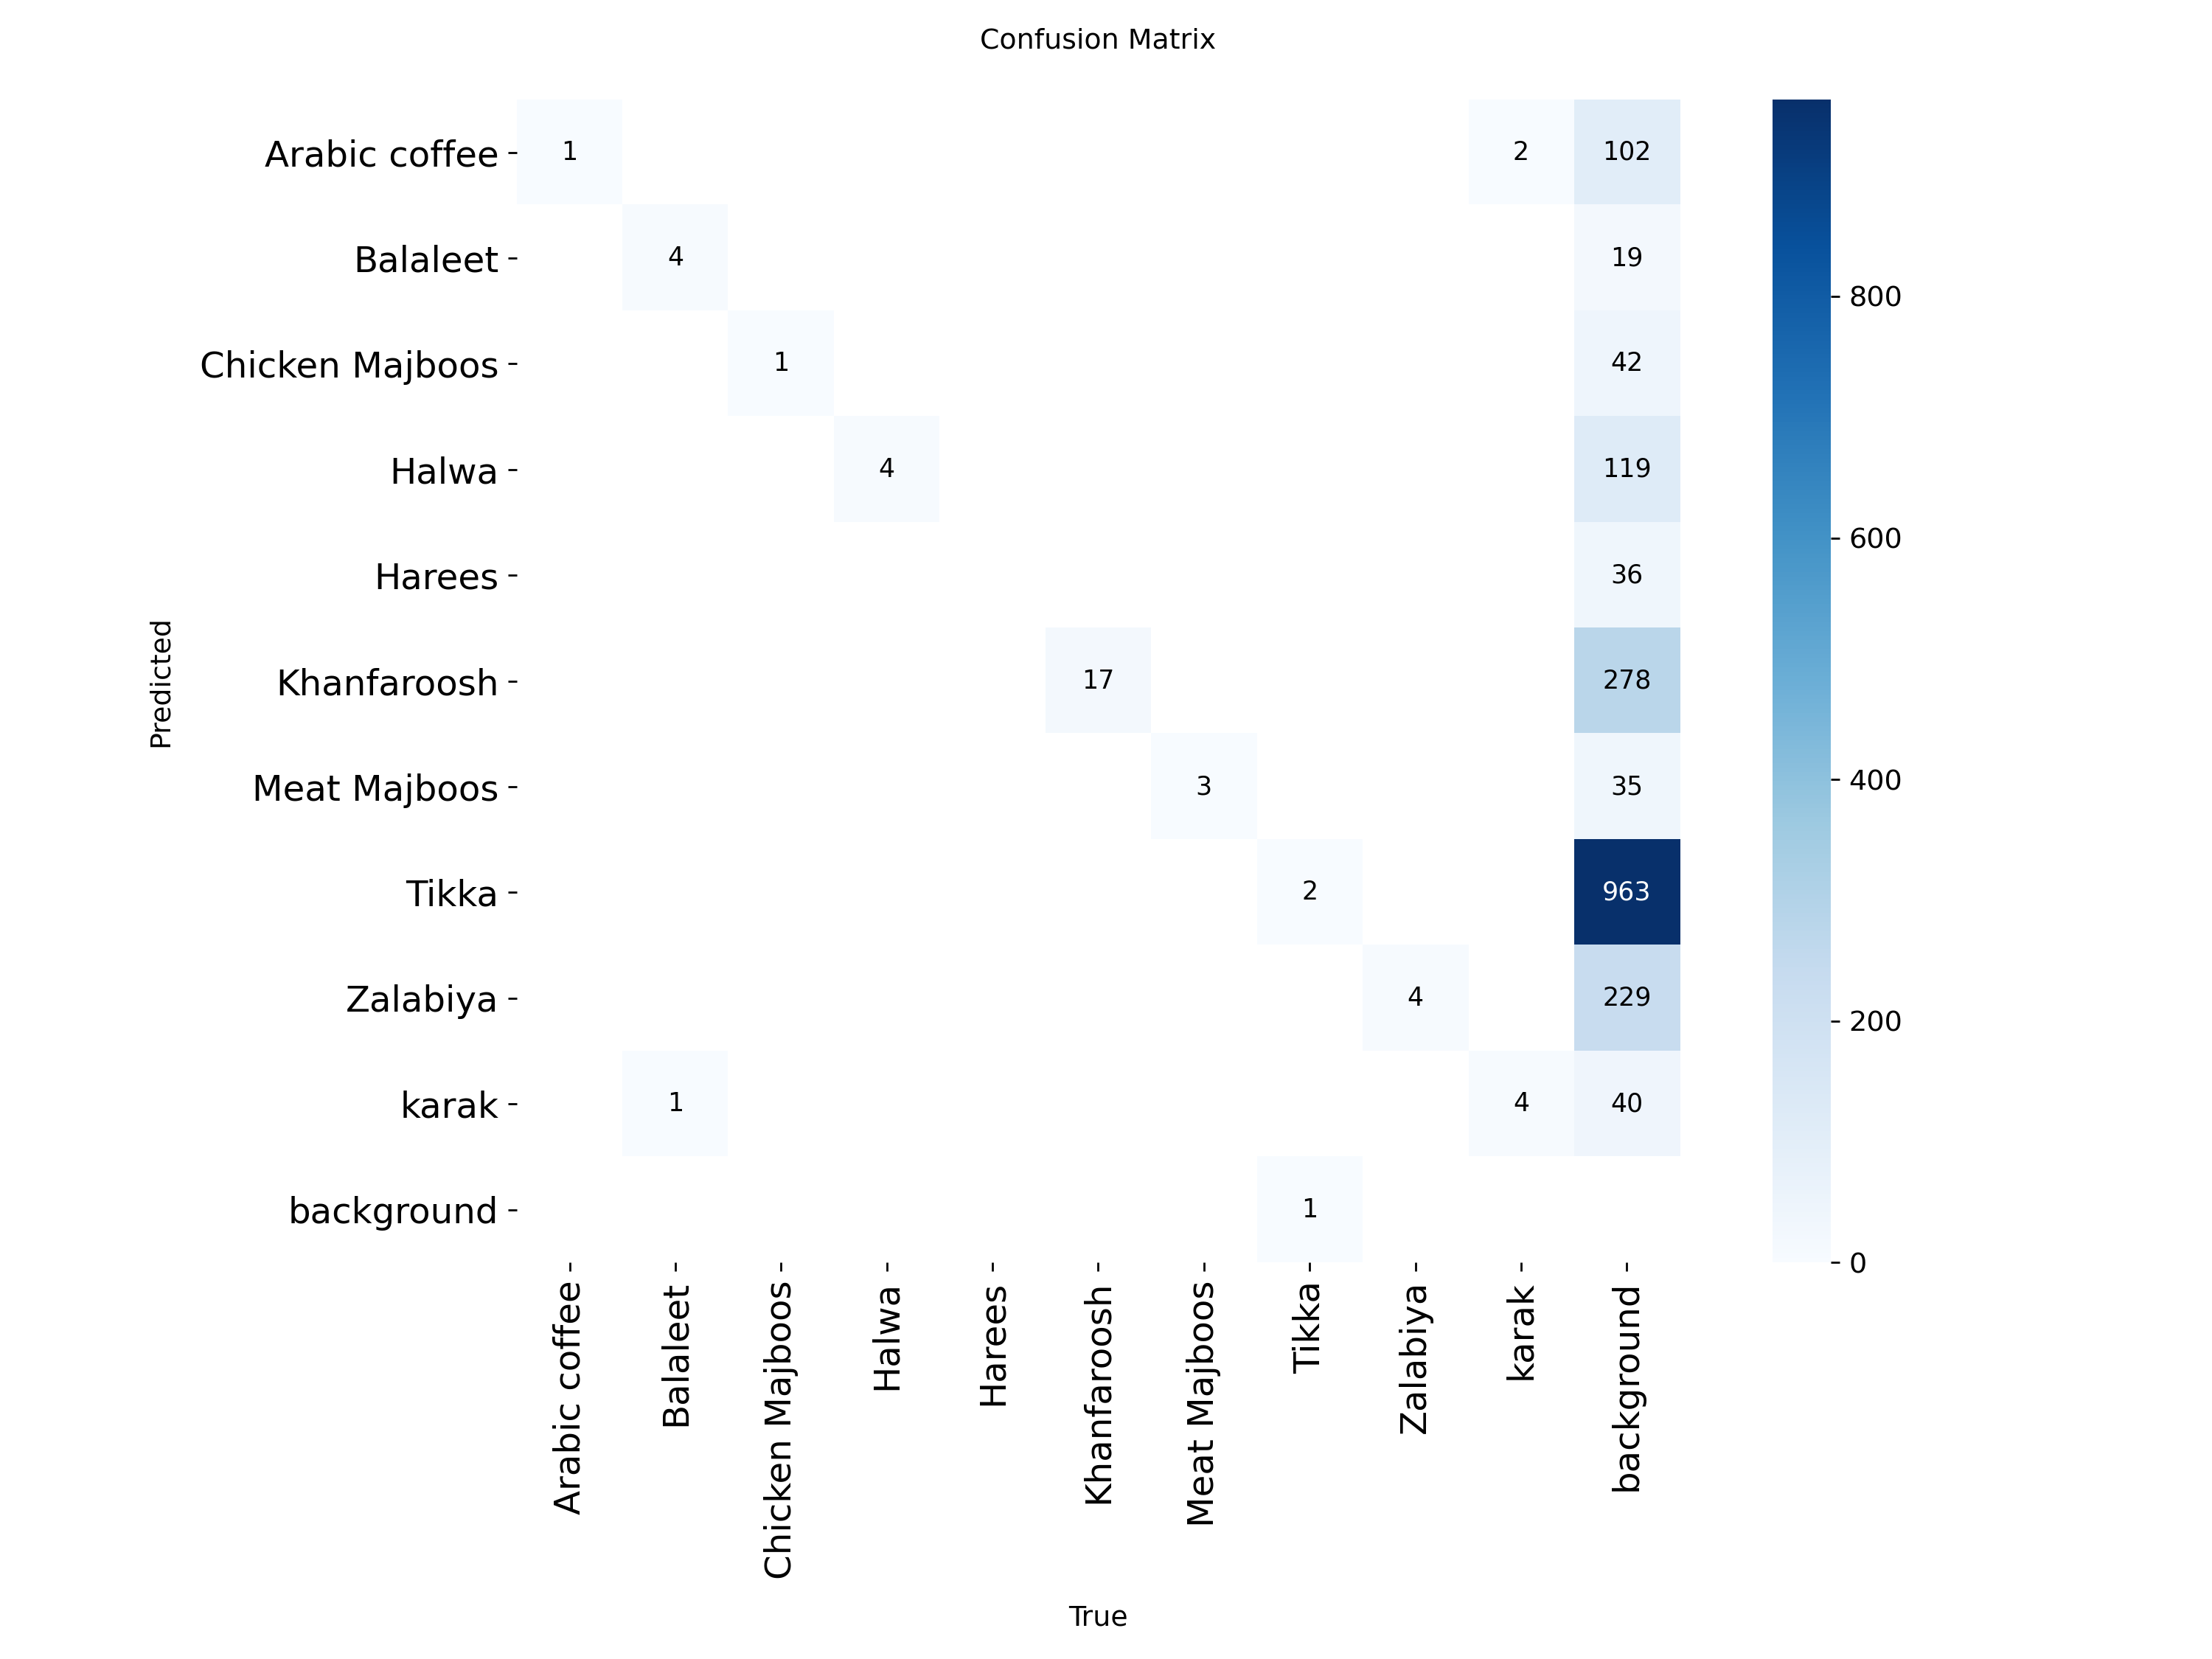

In [ ]:
from IPython.display import Image
res = finetuned_model.val(data="/content/Bahraini-Traditional-Food-1/data.yaml", split="test")
print("Precision:", res.box.mp)
print("Recall:", res.box.mr)

Image("runs/detect/val/confusion_matrix.png")